# 1. Data exploration — air quality in Abidjan

**Prerequisite:** `aaqa fetch process` (or `make data`) has been run.

Data: hourly pollution from the **Copernicus CAMS** model and **ERA5** weather, via Open-Meteo, for
one point in central Abidjan (5.36° N, 4.01° W). The CAMS grid is ~40 km, so the values describe the
whole city, not a district.

Pollutants: PM2.5, PM10, NO2, SO2, O3, CO and desert dust. Weather: temperature, humidity, rain,
wind, pressure.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aaqa import config as paths
from aaqa.aqi import WHO_PM25_24H, WHO_PM25_ANNUAL
from aaqa.pipeline import load_daily, load_hourly
from aaqa.pollutants import POLLUTANTS

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.precision", 2)

In [2]:
hourly, daily = load_hourly(), load_daily()
print(f"{len(hourly):,} hours, {daily['pm2_5_mean'].count()} days "
      f"({daily.index.min():%d/%m/%Y} → {daily.index.max():%d/%m/%Y})")
hourly.describe().T[["mean", "std", "min", "50%", "max"]]

36,960 hours, 1540 days (04/08/2022 → 21/10/2026)


,mean,std,min,50%,max
pm2_5,14.09,10.98,0.4,11.2,133.6
pm10,25.36,20.17,0.6,19.9,233.8
nitrogen_dioxide,1.71,1.79,0.0,1.3,34.4
ozone,54.76,14.64,18.0,53.0,171.0
carbon_monoxide,238.41,127.67,59.0,205.0,2184.0
sulphur_dioxide,0.81,0.65,0.0,0.6,10.3
dust,12.22,21.28,0.0,4.0,222.0
temperature_2m,26.01,2.13,18.4,25.8,34.3
relative_humidity_2m,85.40,9.63,22.0,88.0,100.0
precipitation,0.18,0.66,0.0,0.0,18.0


## Data quality
Share of missing values after cleaning (gaps of up to 6 hours are interpolated):

In [3]:
(hourly.isna().mean() * 100).round(2).rename("% missing").to_frame().T

,pm2_5,pm10,nitrogen_dioxide,ozone,carbon_monoxide,sulphur_dioxide,dust,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure
% missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Every pollutant against its WHO guideline
Each pollutant is studied on the statistic used by the air-quality index (24-hour mean for
particles, 8-hour peak for O3 and CO, hourly peak for NO2 and SO2). The WHO guideline is compared
with the statistic it is defined on.

In [4]:
rows = {}
for key, spec in POLLUTANTS.items():
    series = daily[spec.target]
    who = daily[spec.who_column]
    harmattan = series.index.month.isin([12, 1, 2])
    rows[spec.name] = {
        "statistic": spec.statistic, "mean": series.mean(), "95th pct": series.quantile(0.95),
        "max": series.max(), "harmattan mean": series[harmattan].mean(),
        "rainy-season mean": series[series.index.month.isin([4, 5, 6, 7])].mean(),
        "WHO guideline": spec.who_label, "% days above WHO": 100 * (who > spec.who_limit).mean(),
    }
pd.DataFrame(rows).T

,statistic,mean,95th pct,max,harmattan mean,rainy-season mean,WHO guideline,% days above WHO
PM2.5,24-h mean,14.09,30.63,125.62,23.72,11.13,15 µg/m³ (24-h),30.58
PM10,24-h mean,25.36,60.29,211.47,45.28,19.41,45 µg/m³ (24-h),8.96
O3,max 8-h mean,63.76,89.89,156.5,80.3,59.62,100 µg/m³ (8-h peak),2.73
NO2,max hourly,3.42,10.6,34.4,3.39,3.31,25 µg/m³ (24-h),0.0
SO2,max hourly,1.21,3.7,10.3,1.41,1.1,40 µg/m³ (24-h),0.0
CO,max 8-h mean,289.52,639.99,1663.5,363.86,258.95,10 mg/m³ (8-h),0.0


## Trends

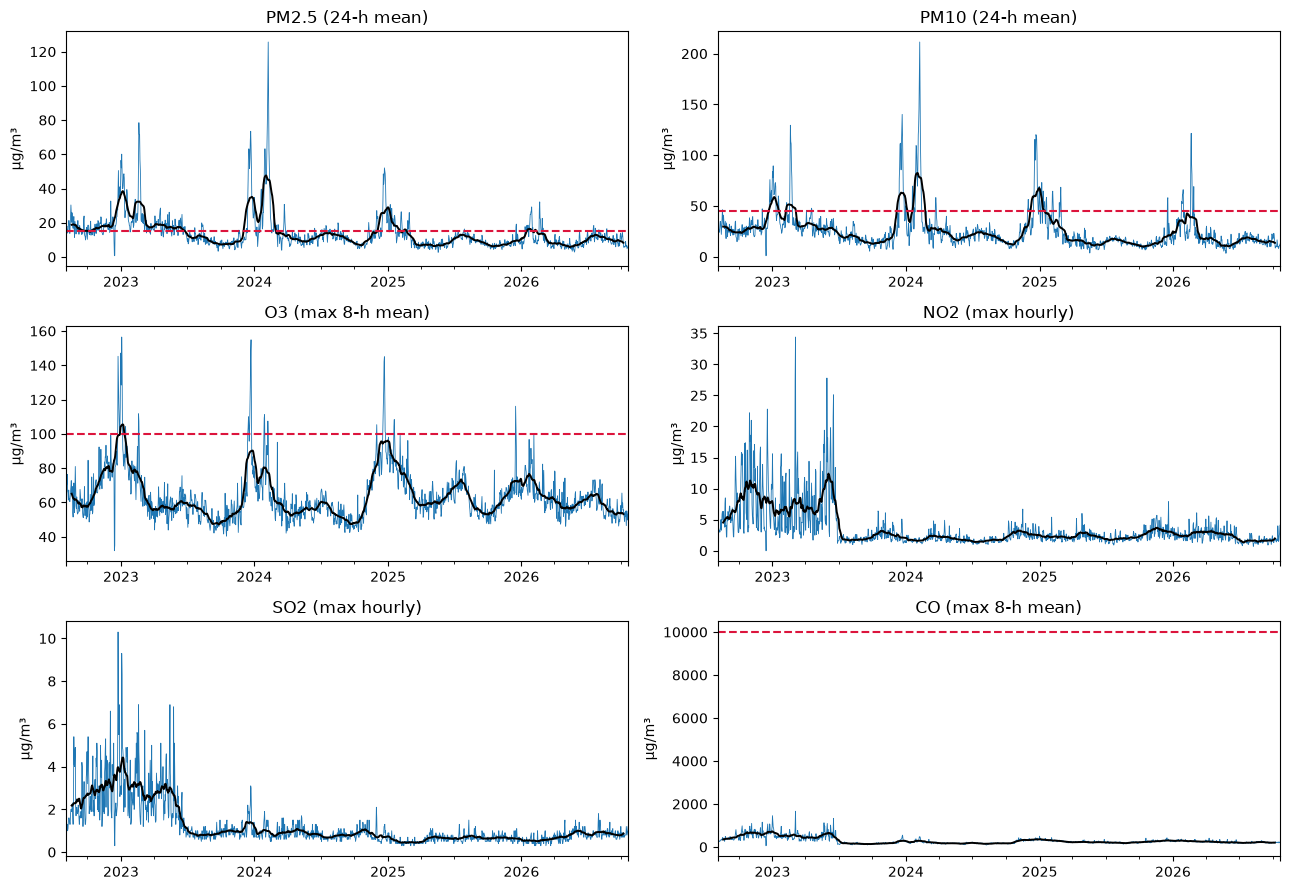

PM2.5 mean: 14.1 µg/m³, i.e. 2.8× the WHO annual guideline


,pm2_5_mean,pm10_mean,ozone_max8h,nitrogen_dioxide_max,sulphur_dioxide_max,carbon_monoxide_max8h
date,,,,,,
2022,18.53,29.36,71.01,7.74,2.79,541.40
2023,17.84,30.15,62.78,4.88,1.87,349.41
2024,15.77,29.70,62.09,2.08,0.86,214.63
2025,10.02,18.98,65.45,2.44,0.62,245.86
2026,10.16,19.88,61.26,2.29,0.76,234.10


In [5]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for ax, (key, spec) in zip(axes.ravel(), POLLUTANTS.items()):
    series = daily[spec.target]
    series.plot(ax=ax, lw=0.6)
    series.rolling(30, center=True).mean().plot(ax=ax, color="black", lw=1.4)
    if spec.who_on_target:
        ax.axhline(spec.who_limit, color="crimson", ls="--")
    ax.set(title=f"{spec.name} ({spec.statistic})", ylabel="µg/m³", xlabel="")
plt.tight_layout(); plt.show()

pm = daily["pm2_5_mean"]
print(f"PM2.5 mean: {pm.mean():.1f} µg/m³, i.e. {pm.mean() / WHO_PM25_ANNUAL:.1f}× the WHO annual guideline")
daily[[spec.target for spec in POLLUTANTS.values()]].groupby(daily.index.year).mean()

## Seasonality: the harmattan
From December to February, the harmattan carries Saharan dust down to the Gulf of Guinea.

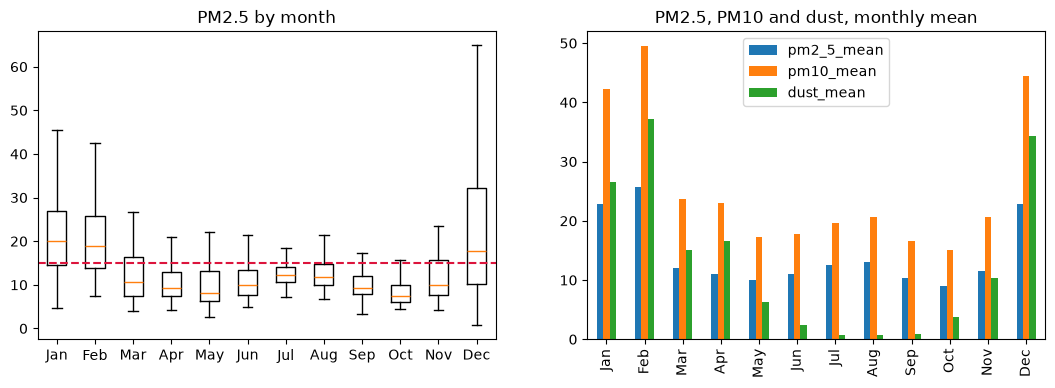

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot([daily.loc[daily.index.month == m, "pm2_5_mean"].dropna() for m in range(1, 13)],
                tick_labels=MONTHS, showfliers=False)
axes[0].set_title("PM2.5 by month"); axes[0].axhline(WHO_PM25_24H, color="crimson", ls="--")
daily.groupby(daily.index.month)[["pm2_5_mean", "pm10_mean", "dust_mean"]].mean().set_axis(MONTHS).plot.bar(ax=axes[1])
axes[1].set_title("PM2.5, PM10 and dust, monthly mean"); plt.show()

## Hourly and weekly cycles

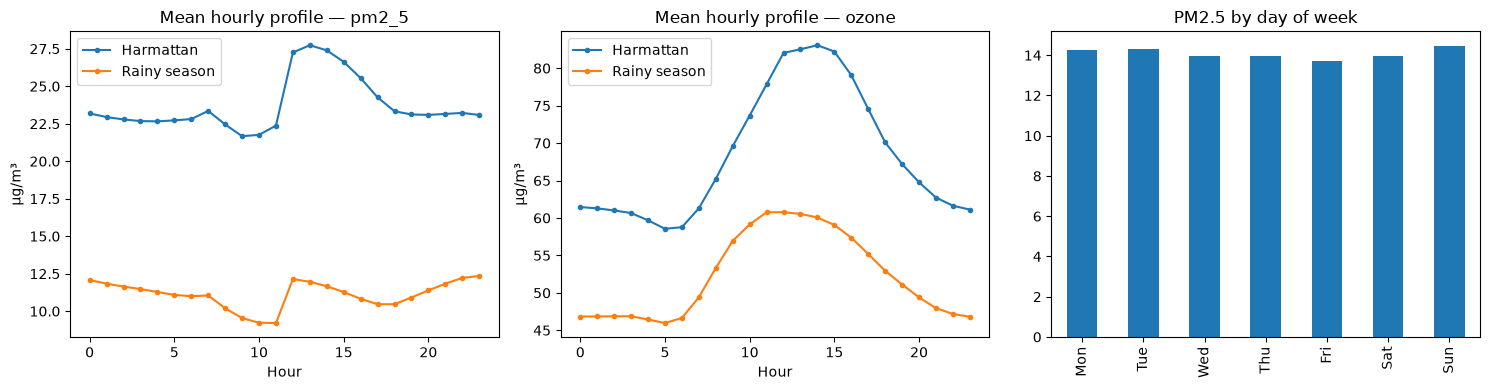

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes[:2], ["pm2_5", "ozone"]):
    for label, m in (("Harmattan", [12, 1, 2]), ("Rainy season", [4, 5, 6, 7])):
        s = hourly[hourly.index.month.isin(m)]
        s.groupby(s.index.hour)[column].mean().plot(ax=ax, marker="o", ms=3, label=label)
    ax.set(title=f"Mean hourly profile — {column}", xlabel="Hour", ylabel="µg/m³"); ax.legend()
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
daily.groupby(daily.index.day_of_week)["pm2_5_mean"].mean().set_axis(days).plot.bar(ax=axes[2], title="PM2.5 by day of week")
plt.tight_layout(); plt.show()

The weekly cycle is almost flat: CAMS is a large-scale model that does not capture local traffic
well. A ground sensor would probably show rush-hour peaks, which is an important limitation (see
`docs/technical_docs.md`). The PM2.5 jump at 12:00 is an artefact of stitching two CAMS forecast
cycles. Ozone peaks in the afternoon, as expected for a pollutant formed in sunlight.

## Pollution–weather correlations

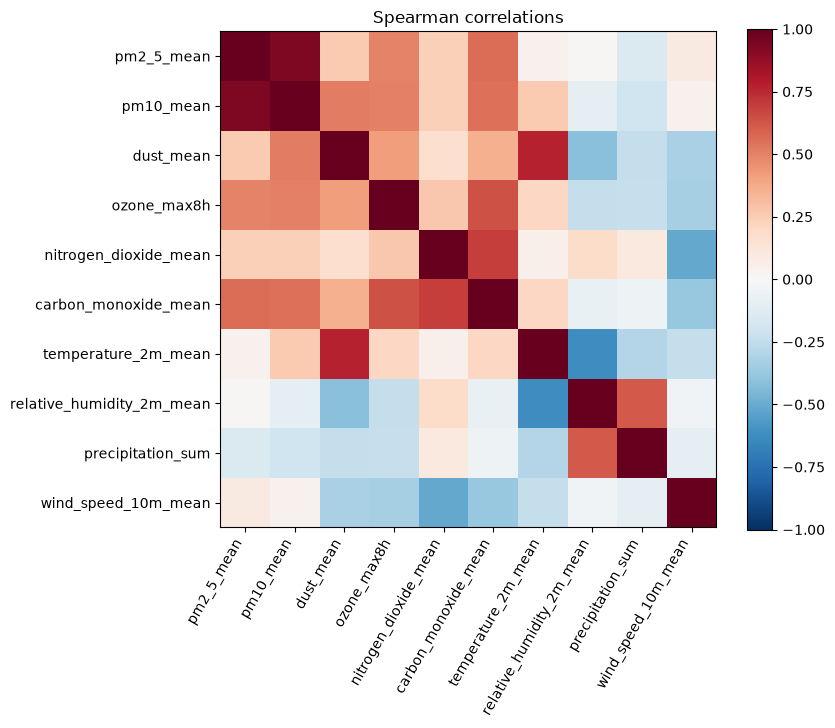

precipitation_sum           -0.15
relative_humidity_2m_mean    0.01
temperature_2m_mean          0.04
wind_speed_10m_mean          0.09
nitrogen_dioxide_mean        0.24
dust_mean                    0.26
ozone_max8h                  0.50
carbon_monoxide_mean         0.56
pm10_mean                    0.93
Name: pm2_5_mean, dtype: float64

In [8]:
cols = ["pm2_5_mean", "pm10_mean", "dust_mean", "ozone_max8h", "nitrogen_dioxide_mean", "carbon_monoxide_mean",
        "temperature_2m_mean", "relative_humidity_2m_mean", "precipitation_sum", "wind_speed_10m_mean"]
corr = daily[cols].corr(method="spearman")
plt.figure(figsize=(8, 6.5)); plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(cols)), cols, rotation=60, ha="right"); plt.yticks(range(len(cols)), cols); plt.colorbar()
plt.title("Spearman correlations"); plt.show()
corr["pm2_5_mean"].drop("pm2_5_mean").sort_values()

## Pollution rose: PM2.5 by wind direction

In [9]:
sectors = (hourly["wind_direction_10m"] // 45 * 45).map({0: "N", 45: "NE", 90: "E", 135: "SE", 180: "S", 225: "SW", 270: "W", 315: "NW", 360: "N"})
hourly.groupby(sectors)[["pm2_5", "pm10"]].mean().join(hourly.groupby(sectors).size().rename("hours")).sort_values("pm2_5", ascending=False)

,pm2_5,pm10,hours
wind_direction_10m,,,
N,26.73,46.59,510
NE,22.35,40.47,289
NW,20.97,36.81,990
E,16.88,31.06,497
SE,15.21,29.06,3253
W,13.75,24.37,2060
S,13.62,24.55,20848
SW,12.91,22.70,8513


## Conclusions
- Particle levels are well above the WHO guidelines: PM2.5 most of all, then PM10.
- Seasonality is dominated by the **harmattan** (Dec–Feb), which doubles PM2.5 and pushes PM10 to its
  guideline. Ozone also rises in that season.
- **North / north-east** winds (harmattan, continental air) bring twice as much PM2.5 as the
  **south** winds from the ocean that blow the rest of the year.
- **CO** is strongly correlated with PM2.5: combustion (biomass fires, wood and charcoal cooking,
  traffic) is the other big source besides dust.
- Humidity has almost no link with PM2.5; rain only a weak one.
- NO2, SO2 and CO stay far below the WHO guidelines in CAMS, almost certainly because the model
  misses local traffic and industry.
- The level has fallen from year to year, so a model must adapt to the recent level rather than
  reproduce the historical mean.